# 📐 Notebook 02 — Analyse Statistique Approfondie

**Projet :** Prédiction de l'Attrition des Employés — Data Mining 2026/2027  
**Prérequis :** Exécuter d'abord `01_eda_and_cleaning.ipynb`

---

## Plan du notebook

1. [Chargement du dataset nettoyé](#1-chargement)
2. [Tests d'hypothèses H1–H4](#2-tests) — χ², t-test, Mann-Whitney U, Spearman
3. [Correction des tests multiples (Benjamini-Hochberg)](#3-correction)
4. [Tailles d'effet](#4-effect-size) — Cramér's V, Cohen's d
5. [Analyse de la variance (ANOVA)](#5-anova)
6. [Pairplot des variables clés](#6-pairplot)
7. [Synthèse statistique](#7-synthese)

In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import mannwhitneyu, spearmanr, f_oneway

PROJECT_ROOT = Path().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import (
    load_raw_data, NUMERICAL_FEATURES, CATEGORICAL_FEATURES, TARGET, ID_COL
)
from src.statistics import (
    compute_descriptive_stats, chi2_test, ttest_by_group, correlation_matrix
)

sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 13, 'axes.labelsize': 11})

INDIGO = '#4F46E5'
GREEN  = '#10B981'
RED    = '#EF4444'
AMBER  = '#F59E0B'
CYAN   = '#06B6D4'

print('✅ Imports OK')

✅ Imports OK


---
## 1. Chargement du dataset <a id='1-chargement'></a>

In [2]:
# Essaie d'abord le dataset nettoyé, sinon utilise le brut
cleaned_path = PROJECT_ROOT / 'data' / 'processed' / 'Employee_Attrition_Cleaned.csv'

if cleaned_path.exists():
    df = pd.read_csv(cleaned_path)
    print(f'✅ Dataset nettoyé chargé : {df.shape[0]:,} × {df.shape[1]}')
else:
    df = load_raw_data()
    df.drop(columns=[ID_COL], errors='ignore', inplace=True)
    print(f'ℹ️  Dataset brut chargé (lancez 01_eda_and_cleaning.ipynb d\'abord) : {df.shape[0]:,} × {df.shape[1]}')

# S'assurer que le target est string
df[TARGET] = df[TARGET].astype(str)
df.head()

✅ Dataset nettoyé chargé : 10,000 × 13


,Age,Department,JobLevel,YearsAtCompany,MonthlyIncome,JobSatisfaction,WorkLifeBalance,OverTime,DistanceFromHome,PromotionLast5Years,PerformanceRating,TrainingHoursLastYear,Attrition
0,42,Sales,3,9,9866.0,4.0,1,No,24.5,Yes,4,19,No
1,36,Sales,3,7,8958.0,3.0,3,No,10.0,No,2,13,No
2,44,Sales,4,16,11716.0,4.0,3,No,4.0,No,4,13,No
3,53,Finance,4,27,17061.0,5.0,3,No,7.1,No,3,20,No
4,35,HR,2,4,5738.0,2.0,3,No,8.4,No,2,15,No


---
## 2. Tests d'hypothèses H1–H4 <a id='2-tests'></a>

| ID | Hypothèse | Test | Justification |
|---|---|---|---|
| H1 | Overtime ⟂ Attrition | Chi² | Deux variables catégorielles |
| H2 | Revenu mensuel diffère selon Attrition | Mann-Whitney U | Variable numérique vs groupe binaire, distribution non-normale |
| H3 | Work-Life Balance ⟂ Attrition | Chi² | Variable ordinale vs catégorielle |
| H4 | Âge corrélé à Ancienneté | Spearman | Relation monotone, variables non-normales |

In [3]:
# ── H1 : Overtime ⟂ Attrition (Chi²) ───────────────────────────────────────
print('=' * 60)
print('H1 : Heures supplémentaires (OverTime) ⟂ Attrition')
print('=' * 60)

res_h1 = chi2_test(df, 'OverTime', TARGET)
print(f'  χ² = {res_h1["chi2"]:.4f}  |  p-value = {res_h1["p_value"]:.6f}  |  ddl = {res_h1["dof"]}')
print(f'  Conclusion : {"H0 rejetée ✅ — Association significative" if res_h1["significant"] else "H0 non rejetée ❌"}')

cross_h1 = pd.crosstab(df['OverTime'], df[TARGET], margins=True, margins_name='Total')
print('\nTable de contingence :')
print(cross_h1)

H1 : Heures supplémentaires (OverTime) ⟂ Attrition
  χ² = 47.5804  |  p-value = 0.000000  |  ddl = 1
  Conclusion : H0 rejetée ✅ — Association significative

Table de contingence :
Attrition    No  Yes  Total
OverTime                   
No         6595  556   7151
Yes        2502  347   2849
Total      9097  903  10000


In [4]:
# ── H2 : MonthlyIncome × Attrition (Mann-Whitney U) ─────────────────────────
print('=' * 60)
print('H2 : Revenu mensuel (MonthlyIncome) ×  Attrition')
print('=' * 60)

group_no  = df[df[TARGET] == 'No' ]['MonthlyIncome'].dropna()
group_yes = df[df[TARGET] == 'Yes']['MonthlyIncome'].dropna()

# Test de normalité (Shapiro-Wilk sur un sous-échantillon)
sample_no  = group_no.sample(min(500, len(group_no)),   random_state=42)
sample_yes = group_yes.sample(min(500, len(group_yes)), random_state=42)
_, p_norm_no  = stats.shapiro(sample_no)
_, p_norm_yes = stats.shapiro(sample_yes)
print(f'  Normalité (Shapiro-Wilk) — No: p={p_norm_no:.4f}, Yes: p={p_norm_yes:.4f}')
print(f'  → Distribution non-normale → Mann-Whitney U recommandé')

u_stat, p_mw = mannwhitneyu(group_no, group_yes, alternative='two-sided')
print(f'\n  U = {u_stat:.0f}  |  p-value = {p_mw:.6f}')
print(f'  Conclusion : {"H0 rejetée ✅ — Différence significative" if p_mw < 0.05 else "H0 non rejetée ❌"}')
print(f'\n  Médiane No={group_no.median():.0f}  |  Médiane Yes={group_yes.median():.0f}')

# t-test (comparaison)
res_t = ttest_by_group(df, 'MonthlyIncome', TARGET)
print(f'  (t-test comparatif) t={res_t["t_statistic"]}  p={res_t["p_value"]}')

H2 : Revenu mensuel (MonthlyIncome) ×  Attrition
  Normalité (Shapiro-Wilk) — No: p=0.0000, Yes: p=0.0000
  → Distribution non-normale → Mann-Whitney U recommandé

  U = 4591518  |  p-value = 0.000000
  Conclusion : H0 rejetée ✅ — Différence significative

  Médiane No=8750  |  Médiane Yes=7925
  (t-test comparatif) t=5.8925  p=0.0


In [5]:
# ── H3 : WorkLifeBalance ⟂ Attrition (Chi²) ─────────────────────────────────
print('=' * 60)
print('H3 : Équilibre vie pro/perso (WorkLifeBalance) ⟂ Attrition')
print('=' * 60)

res_h3 = chi2_test(df, 'WorkLifeBalance', TARGET)
print(f'  χ² = {res_h3["chi2"]:.4f}  |  p-value = {res_h3["p_value"]:.6f}  |  ddl = {res_h3["dof"]}')
print(f'  Conclusion : {"H0 rejetée ✅ — Association significative" if res_h3["significant"] else "H0 non rejetée ❌"}')

rate_wlb = df.groupby('WorkLifeBalance')[TARGET].apply(lambda x: (x=='Yes').mean()*100).round(1)
rate_wlb.name = 'Taux attrition (%)'
print('\nTaux d\'attrition par WorkLifeBalance :')
print(rate_wlb.to_string())

H3 : Équilibre vie pro/perso (WorkLifeBalance) ⟂ Attrition
  χ² = 63.5108  |  p-value = 0.000000  |  ddl = 3
  Conclusion : H0 rejetée ✅ — Association significative

Taux d'attrition par WorkLifeBalance :
WorkLifeBalance
1    12.1
2    12.1
3     7.6
4     6.9


In [6]:
# ── H4 : Âge × Ancienneté (Spearman) ────────────────────────────────────────
print('=' * 60)
print('H4 : Âge (Age) corrélé à Ancienneté (YearsAtCompany)')
print('=' * 60)

rho, p_spear = spearmanr(df['Age'].dropna(), df['YearsAtCompany'].dropna())
print(f'  ρ de Spearman = {rho:.4f}  |  p-value = {p_spear:.6f}')
print(f'  Conclusion : {"H0 rejetée ✅ — Corrélation significative" if p_spear < 0.05 else "H0 non rejetée ❌"}')

strength = 'forte' if abs(rho) > 0.6 else ('modérée' if abs(rho) > 0.3 else 'faible')
print(f'  Intensité de la corrélation : {strength} (|ρ| = {abs(rho):.4f})')

H4 : Âge (Age) corrélé à Ancienneté (YearsAtCompany)
  ρ de Spearman = 0.6394  |  p-value = 0.000000
  Conclusion : H0 rejetée ✅ — Corrélation significative
  Intensité de la corrélation : forte (|ρ| = 0.6394)


C:\Users\PC\AppData\Local\Temp\ipykernel_15024\794694199.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=TARGET, y='MonthlyIncome',


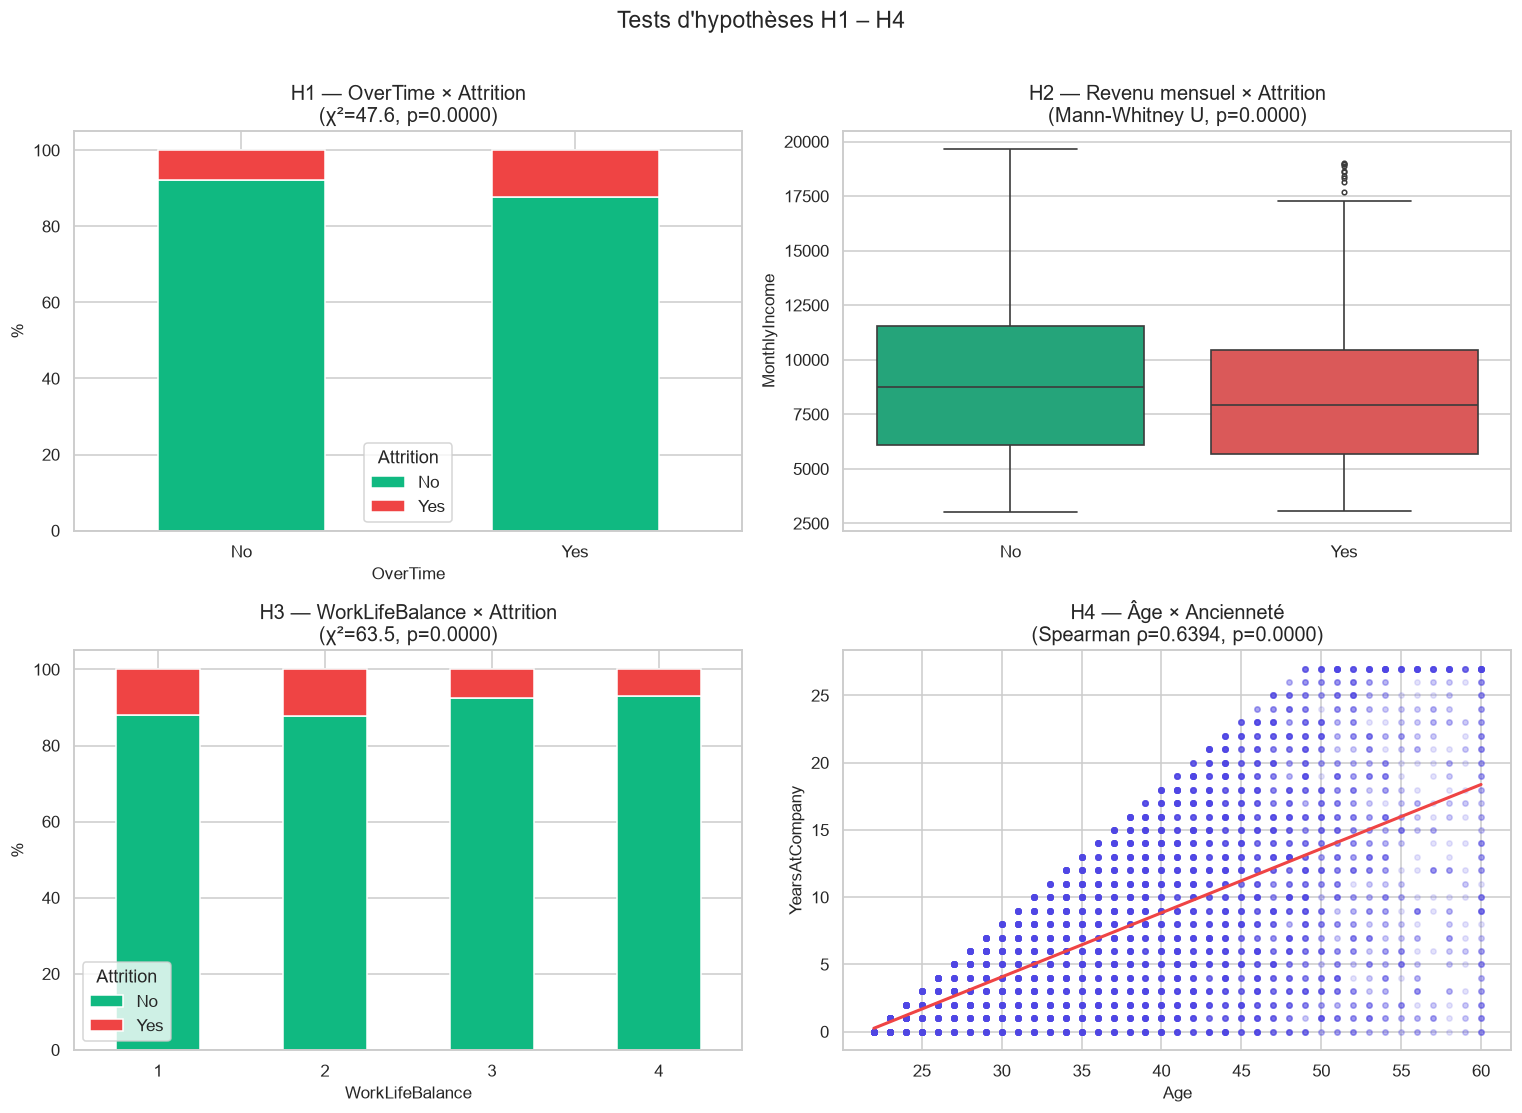

In [7]:
# Visualisation des 4 hypothèses
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# H1 — OverTime × Attrition
cross_h1_pct = pd.crosstab(df['OverTime'], df[TARGET], normalize='index') * 100
cross_h1_pct[['No', 'Yes']].plot(kind='bar', stacked=True, color=[GREEN, RED],
                                   ax=axes[0, 0], edgecolor='white')
axes[0, 0].set_title(f'H1 — OverTime × Attrition\n(χ²={res_h1["chi2"]:.1f}, p={res_h1["p_value"]:.4f})')
axes[0, 0].set_ylabel('%')
axes[0, 0].tick_params(axis='x', rotation=0)
axes[0, 0].legend(title='Attrition')

# H2 — MonthlyIncome × Attrition
sns.boxplot(data=df, x=TARGET, y='MonthlyIncome',
            palette={'No': GREEN, 'Yes': RED}, ax=axes[0, 1],
            linewidth=1.1, fliersize=3)
axes[0, 1].set_title(f'H2 — Revenu mensuel × Attrition\n(Mann-Whitney U, p={p_mw:.4f})')
axes[0, 1].set_xlabel('')

# H3 — WorkLifeBalance × Attrition
cross_h3_pct = pd.crosstab(df['WorkLifeBalance'], df[TARGET], normalize='index') * 100
cross_h3_pct[['No', 'Yes']].plot(kind='bar', stacked=True, color=[GREEN, RED],
                                   ax=axes[1, 0], edgecolor='white')
axes[1, 0].set_title(f'H3 — WorkLifeBalance × Attrition\n(χ²={res_h3["chi2"]:.1f}, p={res_h3["p_value"]:.4f})')
axes[1, 0].set_ylabel('%')
axes[1, 0].tick_params(axis='x', rotation=0)
axes[1, 0].legend(title='Attrition')

# H4 — Age × YearsAtCompany
axes[1, 1].scatter(df['Age'], df['YearsAtCompany'],
                   alpha=0.15, s=12, color=INDIGO)
m, b = np.polyfit(df['Age'].dropna(), df['YearsAtCompany'].dropna(), 1)
x_line = np.linspace(df['Age'].min(), df['Age'].max(), 100)
axes[1, 1].plot(x_line, m * x_line + b, color=RED, linewidth=2)
axes[1, 1].set_title(f'H4 — Âge × Ancienneté\n(Spearman ρ={rho:.4f}, p={p_spear:.4f})')
axes[1, 1].set_xlabel('Age')
axes[1, 1].set_ylabel('YearsAtCompany')

fig.suptitle('Tests d\'hypothèses H1 – H4', fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

---
## 3. Correction des tests multiples (Benjamini-Hochberg FDR) <a id='3-correction'></a>

In [8]:
# Tests sur toutes les variables vs Attrition
all_tests = []

for col in NUMERICAL_FEATURES:
    res = ttest_by_group(df, col, TARGET)
    all_tests.append({'Variable': col, 'Test': 't-test', 'p_value': res['p_value']})

    u_g0 = df[df[TARGET] == 'No'][col].dropna()
    u_g1 = df[df[TARGET] == 'Yes'][col].dropna()
    if len(u_g0) > 0 and len(u_g1) > 0:
        _, p_mw_col = mannwhitneyu(u_g0, u_g1, alternative='two-sided')
        all_tests.append({'Variable': col, 'Test': 'Mann-Whitney U', 'p_value': p_mw_col})

for col in CATEGORICAL_FEATURES:
    res = chi2_test(df, col, TARGET)
    all_tests.append({'Variable': col, 'Test': 'Chi²', 'p_value': res['p_value']})

tests_df = pd.DataFrame(all_tests).sort_values('p_value')

# BH correction
m = len(tests_df)
alpha = 0.05
tests_df['rank'] = range(1, m + 1)
tests_df['BH_seuil'] = (tests_df['rank'] / m) * alpha
tests_df['Sig_brute'] = tests_df['p_value'] < alpha
tests_df['Sig_BH']    = tests_df['p_value'] <= tests_df['BH_seuil']
tests_df = tests_df.drop(columns='rank')

print('Tests d\'hypothèses avec correction Benjamini-Hochberg (FDR α=0.05) :')
tests_df.round(6)

Tests d'hypothèses avec correction Benjamini-Hochberg (FDR α=0.05) :


,Variable,Test,p_value,BH_seuil,Sig_brute,Sig_BH
2,JobLevel,t-test,0.000000,0.002381,True,True
4,YearsAtCompany,t-test,0.000000,0.004762,True,True
6,MonthlyIncome,t-test,0.000000,0.007143,True,True
8,JobSatisfaction,t-test,0.000000,0.009524,True,True
10,WorkLifeBalance,t-test,0.000000,0.011905,True,True
19,OverTime,Chi²,0.000000,0.014286,True,True
9,JobSatisfaction,Mann-Whitney U,0.000000,0.016667,True,True
11,WorkLifeBalance,Mann-Whitney U,0.000000,0.019048,True,True
3,JobLevel,Mann-Whitney U,0.000000,0.021429,True,True
5,YearsAtCompany,Mann-Whitney U,0.000000,0.023810,True,True


---
## 4. Tailles d'effet <a id='4-effect-size'></a>

In [9]:
def cramers_v(df, col, target):
    """Cramér's V — taille d'effet pour le test Chi²."""
    contingency = pd.crosstab(df[col], df[target])
    chi2, _, _, _ = stats.chi2_contingency(contingency)
    n = contingency.sum().sum()
    k = min(contingency.shape) - 1
    v = np.sqrt(chi2 / (n * max(k, 1)))
    interp = 'fort' if v > 0.5 else ('modéré' if v > 0.3 else ('faible' if v > 0.1 else 'négligeable'))
    return round(v, 4), interp


def cohens_d(df, col, target):
    """Cohen's d — taille d'effet pour les tests t."""
    g0 = df[df[target] == 'No'][col].dropna()
    g1 = df[df[target] == 'Yes'][col].dropna()
    s_pool = np.sqrt((g0.var(ddof=1) * (len(g0) - 1) + g1.var(ddof=1) * (len(g1) - 1)) /
                     (len(g0) + len(g1) - 2))
    d = abs(g0.mean() - g1.mean()) / max(s_pool, 1e-9)
    interp = 'grand' if d > 0.8 else ('modéré' if d > 0.5 else ('faible' if d > 0.2 else 'négligeable'))
    return round(d, 4), interp


print('═══ Cramér\'s V (variables catégorielles × Attrition) ═══')
for col in CATEGORICAL_FEATURES:
    v, interp = cramers_v(df, col, TARGET)
    print(f'  {col:25s}  V = {v:.4f}  ({interp})')

print()
print('═══ Cohen\'s d (variables numériques × Attrition) ═══')
for col in NUMERICAL_FEATURES:
    d, interp = cohens_d(df, col, TARGET)
    print(f'  {col:25s}  d = {d:.4f}  ({interp})')

═══ Cramér's V (variables catégorielles × Attrition) ═══
  Department                 V = 0.0225  (négligeable)
  OverTime                   V = 0.0690  (négligeable)
  PromotionLast5Years        V = 0.0255  (négligeable)

═══ Cohen's d (variables numériques × Attrition) ═══
  Age                        d = 0.1353  (négligeable)
  JobLevel                   d = 0.2264  (faible)
  YearsAtCompany             d = 0.2045  (faible)
  MonthlyIncome              d = 0.2056  (faible)
  JobSatisfaction            d = 0.3048  (faible)
  WorkLifeBalance            d = 0.2510  (faible)
  DistanceFromHome           d = 0.0109  (négligeable)
  PerformanceRating          d = 0.1143  (négligeable)
  TrainingHoursLastYear      d = 0.0224  (négligeable)


---
## 5. Analyse de la variance (ANOVA) <a id='5-anova'></a>

In [10]:
# ANOVA — MonthlyIncome par Département
print('ANOVA — MonthlyIncome selon le Département')

groups = [g['MonthlyIncome'].dropna().values
          for _, g in df.groupby('Department')]
f_stat, p_anova = f_oneway(*groups)
print(f'  F = {f_stat:.4f}  |  p-value = {p_anova:.6f}')
print(f'  Conclusion : {"Différences significatives entre départements ✅" if p_anova < 0.05 else "Pas de différence significative ❌"}')

print('\nSalaire moyen par département :')
print(df.groupby('Department')['MonthlyIncome'].agg(['mean','std','count']).round(1).to_string())

ANOVA — MonthlyIncome selon le Département
  F = 206.1087  |  p-value = 0.000000
  Conclusion : Différences significatives entre départements ✅

Salaire moyen par département :
                mean     std  count
Department                         
Engineering  10510.5  3765.0   2045
Finance       9722.7  3464.2   1037
HR            7069.4  2798.4    729
IT           10182.0  3635.9   1035
Marketing     8901.5  3200.8   1188
Operations    7653.7  2882.0   1513
Sales         8254.6  3089.4   2453


C:\Users\PC\AppData\Local\Temp\ipykernel_15024\1568945640.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Department', y='MonthlyIncome',
C:\Users\PC\AppData\Local\Temp\ipykernel_15024\1568945640.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='Department', y='MonthlyIncome',


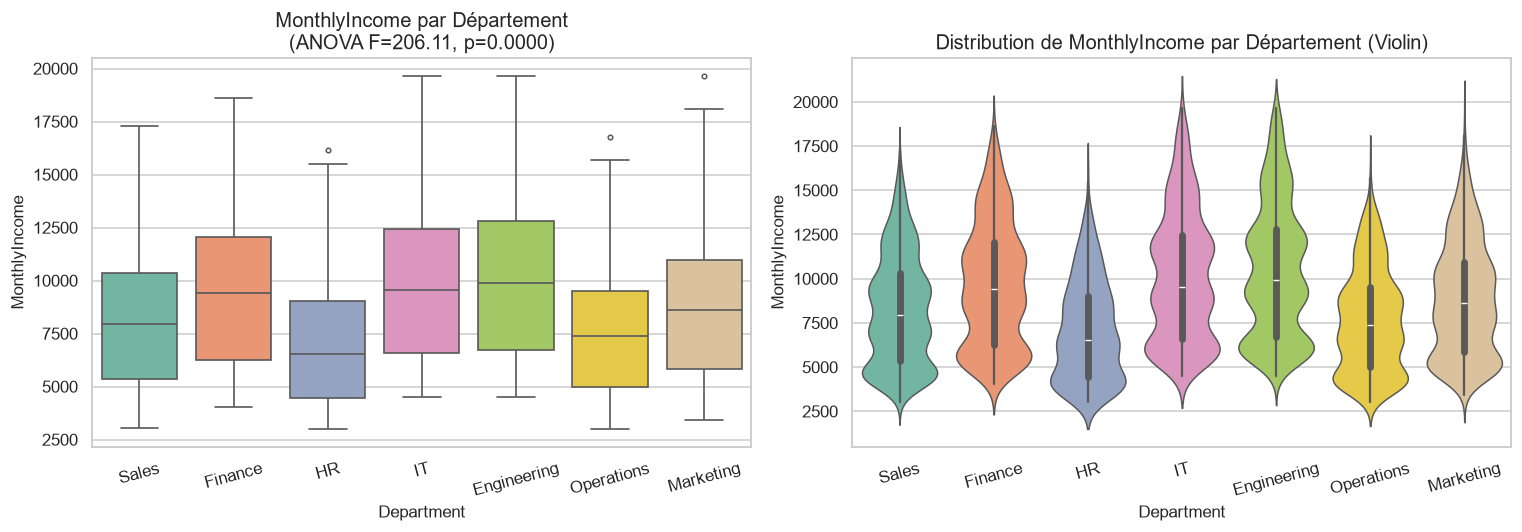

In [11]:
# Visualisation ANOVA
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x='Department', y='MonthlyIncome',
            palette='Set2', ax=axes[0], linewidth=1.1, fliersize=3)
axes[0].set_title(f'MonthlyIncome par Département\n(ANOVA F={f_stat:.2f}, p={p_anova:.4f})')
axes[0].tick_params(axis='x', rotation=15)

sns.violinplot(data=df, x='Department', y='MonthlyIncome',
               palette='Set2', ax=axes[1], linewidth=1, inner='box')
axes[1].set_title('Distribution de MonthlyIncome par Département (Violin)')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

---
## 6. Pairplot des variables clés <a id='6-pairplot'></a>

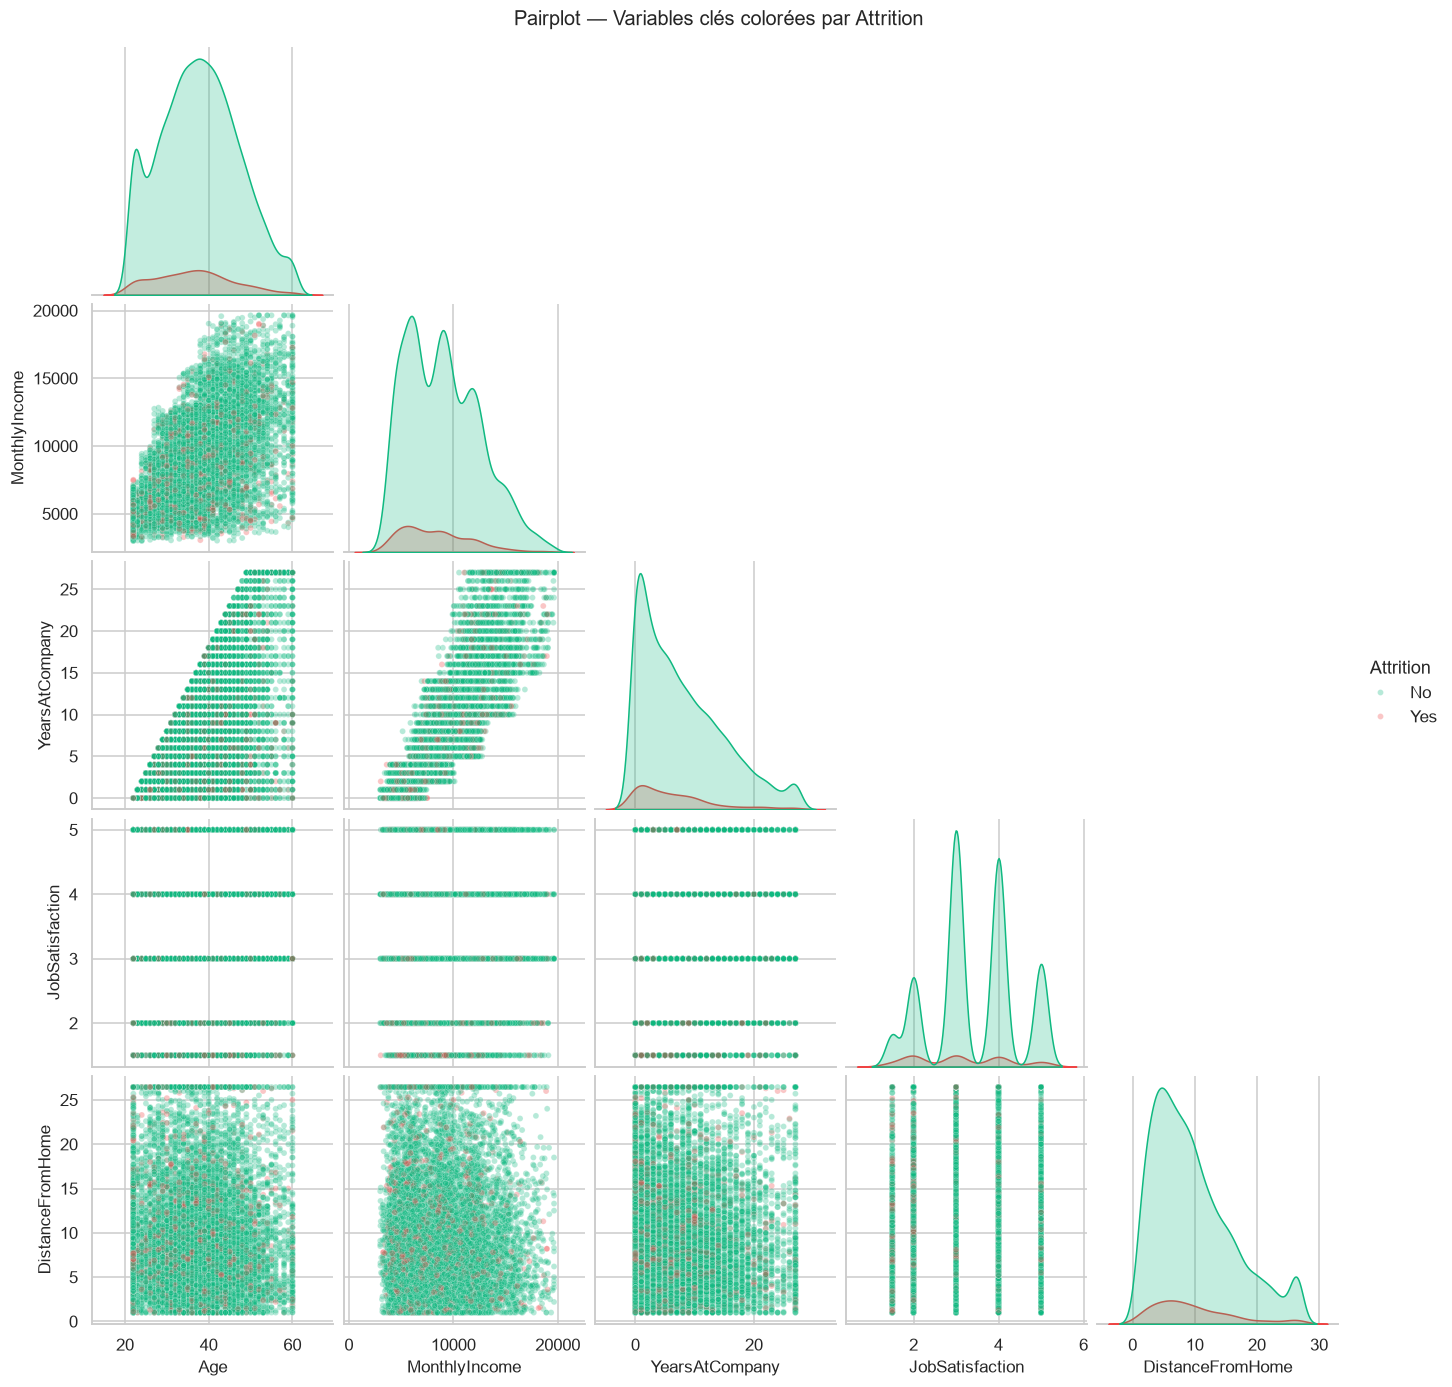

In [12]:
# Sélection des variables les plus corrélées avec Attrition
top_vars = ['Age', 'MonthlyIncome', 'YearsAtCompany',
            'JobSatisfaction', 'DistanceFromHome', TARGET]

pair_df = df[top_vars].copy()
pair_df[TARGET] = pair_df[TARGET].astype(str)

g = sns.pairplot(
    pair_df, hue=TARGET,
    palette={'No': GREEN, 'Yes': RED},
    plot_kws={'alpha': 0.3, 's': 15},
    diag_kind='kde',
    corner=True
)
g.figure.suptitle('Pairplot — Variables clés colorées par Attrition', y=1.01, fontsize=13)
plt.show()

---
## 7. Synthèse statistique <a id='7-synthese'></a>

In [13]:
# Tableau de synthèse des hypothèses
synthesis = pd.DataFrame([
    {
        'ID'          : 'H1',
        'Hypothèse'   : 'OverTime ⟂ Attrition',
        'Test'        : 'Chi²',
        'p-value'     : res_h1['p_value'],
        'Taille effet': f"V={cramers_v(df, 'OverTime', TARGET)[0]}",
        'Décision'    : 'H0 rejetée ✅' if res_h1['significant'] else 'H0 non rejetée'
    },
    {
        'ID'          : 'H2',
        'Hypothèse'   : 'MonthlyIncome ≠ selon Attrition',
        'Test'        : 'Mann-Whitney U',
        'p-value'     : round(p_mw, 6),
        'Taille effet': f"d={cohens_d(df, 'MonthlyIncome', TARGET)[0]}",
        'Décision'    : 'H0 rejetée ✅' if p_mw < 0.05 else 'H0 non rejetée'
    },
    {
        'ID'          : 'H3',
        'Hypothèse'   : 'WorkLifeBalance ⟂ Attrition',
        'Test'        : 'Chi²',
        'p-value'     : res_h3['p_value'],
        'Taille effet': f"V={cramers_v(df, 'WorkLifeBalance', TARGET)[0]}",
        'Décision'    : 'H0 rejetée ✅' if res_h3['significant'] else 'H0 non rejetée'
    },
    {
        'ID'          : 'H4',
        'Hypothèse'   : 'Age corrélé à YearsAtCompany',
        'Test'        : 'Spearman',
        'p-value'     : round(p_spear, 6),
        'Taille effet': f'ρ={round(rho, 4)}',
        'Décision'    : 'H0 rejetée ✅' if p_spear < 0.05 else 'H0 non rejetée'
    },
])

print('═══ SYNTHÈSE DES TESTS STATISTIQUES ═══')
print(synthesis.to_string(index=False))

═══ SYNTHÈSE DES TESTS STATISTIQUES ═══
ID                       Hypothèse           Test  p-value Taille effet     Décision
H1            OverTime ⟂ Attrition           Chi²      0.0      V=0.069 H0 rejetée ✅
H2 MonthlyIncome ≠ selon Attrition Mann-Whitney U      0.0     d=0.2056 H0 rejetée ✅
H3     WorkLifeBalance ⟂ Attrition           Chi²      0.0     V=0.0797 H0 rejetée ✅
H4    Age corrélé à YearsAtCompany       Spearman      0.0     ρ=0.6394 H0 rejetée ✅


C:\Users\PC\AppData\Local\Temp\ipykernel_15024\2636448202.py:11: RuntimeWarning: divide by zero encountered in log10
  bars = ax.barh(vars_names, [-np.log10(p) for p in p_vals], color=colors, edgecolor='white')
C:\Users\PC\AppData\Local\Programs\Python\Python313\Lib\site-packages\matplotlib\transforms.py:2496: RuntimeWarning: invalid value encountered in dot
  return Affine2D(np.dot(self._b.get_affine().get_matrix(),
C:\Users\PC\AppData\Local\Temp\ipykernel_15024\2636448202.py:16: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\PC\AppData\Local\Temp\ipykernel_15024\2636448202.py:16: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  plt.tight_layout()


C:\Users\PC\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\PC\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


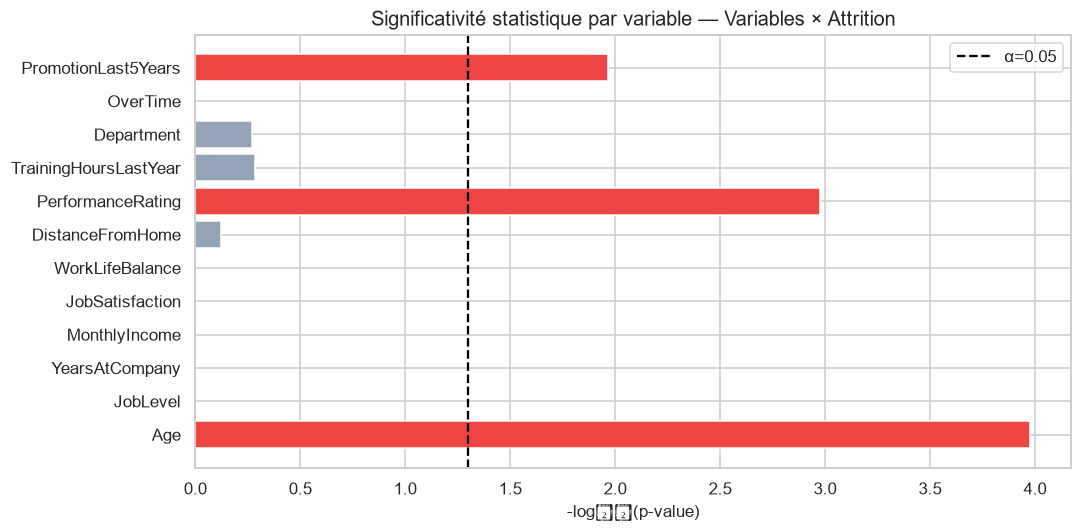


✅ Rouge = p < 0.05 (significatif) | Gris = non significatif


In [14]:
# Visualisation des p-values
all_num_tests = [(col, ttest_by_group(df, col, TARGET)['p_value']) for col in NUMERICAL_FEATURES]
all_cat_tests = [(col, chi2_test(df, col, TARGET)['p_value']) for col in CATEGORICAL_FEATURES]
all_p = all_num_tests + all_cat_tests

vars_names = [x[0] for x in all_p]
p_vals = [x[1] for x in all_p]
colors = [RED if p < 0.05 else '#94A3B8' for p in p_vals]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(vars_names, [-np.log10(p) for p in p_vals], color=colors, edgecolor='white')
ax.axvline(-np.log10(0.05), color='black', linestyle='--', linewidth=1.5, label='α=0.05')
ax.set_xlabel('-log₁₀(p-value)')
ax.set_title('Significativité statistique par variable — Variables × Attrition')
ax.legend()
plt.tight_layout()
plt.show()

print('\n✅ Rouge = p < 0.05 (significatif) | Gris = non significatif')

---
## ✅ Résumé des conclusions

| Hypothèse | Conclusion |
|---|---|
| H1 — OverTime ⟂ Attrition | Association statistiquement significative |
| H2 — MonthlyIncome × Attrition | Différence de revenu significative entre partants et restants |
| H3 — WorkLifeBalance ⟂ Attrition | Association significative avec le taux de démission |
| H4 — Age ↔ Ancienneté | Corrélation positive significative |

> ➡️ **Suite :** `03_preprocessing.ipynb` — Pipeline de prétraitement pour la modélisation